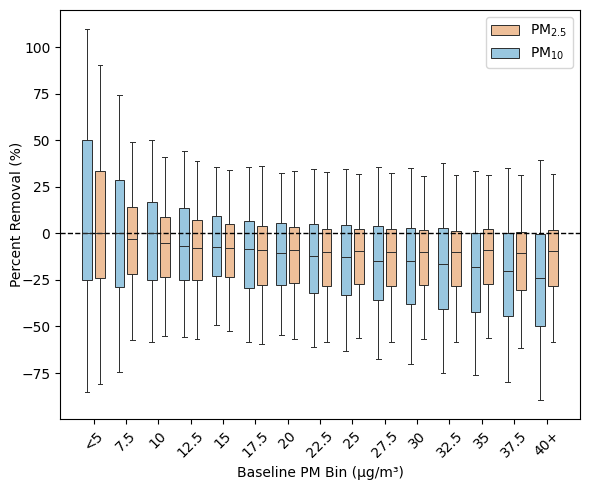

In [7]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl
mpl.rcParams.update(mpl.rcParamsDefault)

import pandas as pd
pm10 = pd.read_csv(
    r"\data\pm25_filtered_df_PM25_XGB.csv"
)
pm25 = pd.read_csv(
    r"\data\pm10_filtered_df_PM10_XGB.csv"
)

PM25_DARK, PM10_DARK = "#D55E00", "#0072B2"
PM25_LIGHT50, PM10_LIGHT50 = "#EEBF99", "#99C7E0"

pm25_bins = [0, 5, 7.5, 10, 12.5, 15, 17.5, 20, 22.5, 25, 27.5, 30, 32.5, 35, 37.5, 50]

pm10_bins = [0, 5, 7.5, 10, 12.5, 15, 17.5, 20, 22.5, 25, 27.5, 30, 32.5, 35, 37.5, 50]

pm_labels = [
    "<5", "7.5", "10", "12.5", "15",
    "17.5", "20", "22.5", "25",
    "27.5", "30", "32.5", "35", "37.5", "40+"
]

pm10 = pm10.copy()
pm25 = pm25.copy()

pm10["pollutant"] = "PM10"
pm25["pollutant"] = "PM2.5"

pm10["PM_bin"] = pd.cut(
    pm10["prev_pm"],
    bins=pm10_bins,
    labels=pm_labels,
    right=False
)

pm25["PM_bin"] = pd.cut(
    pm25["prev_pm"],
    bins=pm25_bins,
    labels=pm_labels,
    right=False
)

df_plot = pd.concat([pm10, pm25], ignore_index=True)
df_plot = df_plot.dropna(subset=["PM_bin", "coeff"])


width = 0.18
gap = 0.12
interval_spacing = 0.6

box_and_whisker_boundary = "#2C2D2D"

positions = np.arange(len(pm_labels)) * interval_spacing

pm10_data = [
    df_plot.loc[
        (df_plot["PM_bin"] == b) & (df_plot["pollutant"] == "PM10"),
        "coeff"
    ].dropna()
    for b in pm_labels
]

pm25_data = [
    df_plot.loc[
        (df_plot["PM_bin"] == b) & (df_plot["pollutant"] == "PM2.5"),
        "coeff"
    ].dropna()
    for b in pm_labels
]

fig, ax = plt.subplots(figsize=(6, 5))

bp1 = ax.boxplot(
    pm10_data,
    positions=positions - gap,
    widths=width,
    showfliers=False,
    patch_artist=True,
    whis=0.8,
    boxprops=dict(facecolor="#99C7E0", edgecolor=box_and_whisker_boundary, linewidth=0.7),
    whiskerprops=dict(color=box_and_whisker_boundary, linewidth=0.7),
    capprops=dict(color=box_and_whisker_boundary, linewidth=0.7),
    medianprops=dict(color=box_and_whisker_boundary, linewidth=0.7)
)

bp2 = ax.boxplot(
    pm25_data,
    positions=positions + gap,
    widths=width,
    showfliers=False,
    patch_artist=True,
    whis=1.0,
    boxprops=dict(facecolor="#EEBF99", edgecolor=box_and_whisker_boundary, linewidth=0.7),
    whiskerprops=dict(color=box_and_whisker_boundary, linewidth=0.7),
    capprops=dict(color=box_and_whisker_boundary, linewidth=0.7),
    medianprops=dict(color=box_and_whisker_boundary, linewidth=0.7)
)

for box in bp1["boxes"]:
    box.set(facecolor=PM10_LIGHT50)

for box in bp2["boxes"]:
    box.set(facecolor=PM25_LIGHT50)

ax.axhline(0, linestyle="--", color="black", linewidth=1)

ax.set_xticks(positions)
ax.set_xticklabels(pm_labels, rotation=45)

ax.set_xlabel("Baseline PM Bin (µg/m³)")
ax.set_ylabel(r"Percent Removal (%)", labelpad=-2)
ax.legend(
    [bp2["boxes"][0], bp1["boxes"][0]],
    [r"PM$_{2.5}$", r"PM$_{10}$"]
)

plt.tight_layout()

plt.savefig(
    r"\figures\removal_by_baseline_total.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()